<a href="https://colab.research.google.com/github/sonakshigupta29/e2e-mass-regression-cmssw/blob/main/01_data_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
BASE = '/content/drive/MyDrive/e2e_mass_regression'
os.makedirs(BASE, exist_ok=True)

Mounted at /content/drive


In [8]:

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/e2e_mass_regression'
!ls -lh "{BASE}"
!cp "{BASE}/top_gun_opendata_0.parquet" /content/
!ls -lh /content/top_gun_opendata_0.parquet

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 1.1G
-rw------- 1 root root  71K Nov 24 10:43 channels.png
-rw------- 1 root root  11K Nov 24 05:55 mass_hist.png
-rw------- 1 root root 1.1G Nov 24 05:43 top_gun_opendata_0.parquet
-rw------- 1 root root 1.1G Nov 24 10:46 /content/top_gun_opendata_0.parquet


In [2]:
!wget -c --content-disposition -O /content/top_gun_opendata_0.parquet "https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet"
!ls -lh /content/top_gun_opendata_0.parquet

--2026-11-24 05:42:18--  https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet
Resolving cernbox.cern.ch (cernbox.cern.ch)... 128.142.53.28, 188.185.200.39, 188.184.19.133, ...
Connecting to cernbox.cern.ch (cernbox.cern.ch)|128.142.53.28|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1171158319 (1.1G) [application/octet-stream]
--2026-11-24 05:42:19--  https://cernbox.cern.ch/remote.php/dav/public-files/zUvpkKhXIp0MJ0g/top_gun_opendata_0.parquet
Reusing existing connection to cernbox.cern.ch:443.
HTTP request sent, awaiting response... 200 OK
Length: 1171158319 (1.1G) [application/octet-stream]
Saving to: ‘/content/top_gun_opendata_0.parquet’

/content/top_gun_op 100%[===================>]   1.09G  17.7MB/s    in 53s     

2026-11-24 05:43:13 (21.0 MB/s) - ‘/content/top_gun_opendata_0.parquet’ saved [1171158319/1171158319]

-rw-r--r-- 1 root root 1.1G Feb 23  2024 /content/top_gun_opendata_0.parquet


In [3]:
!cp /content/top_gun_opendata_0.parquet /content/drive/MyDrive/e2e_mass_regression/

Checking schema of the data

In [3]:
import pyarrow.parquet as pq
pf = pq.ParquetFile(f'{BASE}/top_gun_opendata_0.parquet')
print(pf.metadata.num_rows, pf.metadata.num_row_groups)
print(pf.schema_arrow)

150327 150327
X_jet: list<item: list<item: list<item: double>>>
  child 0, item: list<item: list<item: double>>
      child 0, item: list<item: double>
          child 0, item: double
m: double
iphi: double
pt: double
ieta: double


150327 85.28666687011719 499.9996643066406 293.28993698248314 292.99078369140625 119.90458159601208
NaN: 0


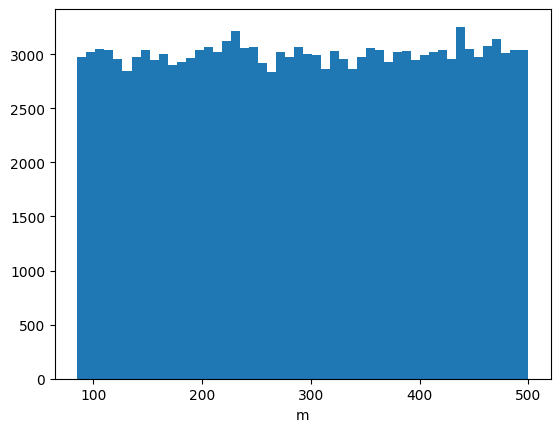

(8, 125, 125)
0 0.0 56.258026 0.00224
1 -485.9448 22.394949 0.001088
2 -84.91347 312.55505 0.001408
3 0.0 72.8135 0.041344
4 0.0 18.54857 0.0048
5 0.0 2.0 0.002496
6 0.0 3.0 0.00224
7 0.0 3.0 0.002816


In [4]:
import numpy as np, matplotlib.pyplot as plt

# the target, for the whole file
t = pf.read(columns=['m']).to_pandas()['m'].values
print(len(t), t.min(), t.max(), t.mean(), np.median(t), t.std())
print('NaN:', np.isnan(t).sum())
plt.hist(t, bins=50); plt.xlabel('m'); plt.savefig('mass_hist.png'); plt.show()

# one sample
rg = pf.read_row_group(0).to_pandas()
x = np.array([[list(row) for row in ch] for ch in rg['X_jet'].values[0]], dtype=np.float32)
print(x.shape)
for c in range(x.shape[0]):
    print(c, x[c].min(), x[c].max(), (x[c] > 0).mean())

In [6]:
!cp mass_hist.png "{BASE}/mass_hist.png"
!ls -lh "{BASE}/mass_hist.png"

-rw------- 1 root root 11K Nov 24 05:55 /content/drive/MyDrive/e2e_mass_regression/mass_hist.png


Closer look to all 8 channels

In [19]:
import numpy as np
xs = []
for k in range(0, 2000, 10):
    r = pf.read_row_group(k).to_pandas()
    xs.append(np.array([[list(row) for row in ch] for ch in r['X_jet'].values[0]], dtype=np.float32))
xs = np.stack(xs)               # (200, 8, 125, 125)
for c in range(8):
    v = xs[:, c][xs[:, c] != 0]
    print(c, len(v), np.percentile(v, [1, 50, 99, 99.9]))

0 5594 [  0.73154726   5.63774157 135.1666272  418.16367032]
1 5594 [-5.03537035e+01 -2.48284754e-03  4.50325349e+01  1.32079104e+02]
2 5594 [-7.74537738e+01  4.94223554e-03  8.43181034e+01  2.86146456e+02]
3 97556 [1.55249890e-03 1.16287712e-01 1.35099256e+01 7.31546980e+01]
4 139325 [6.24682568e-03 1.27778813e-01 6.53646469e+00 1.58996000e+01]
5 6106 [1.    1.    2.    3.895]
6 6628 [1. 1. 3. 4.]
7 6784 [1. 1. 3. 5.]


Plot to understand 8 channels

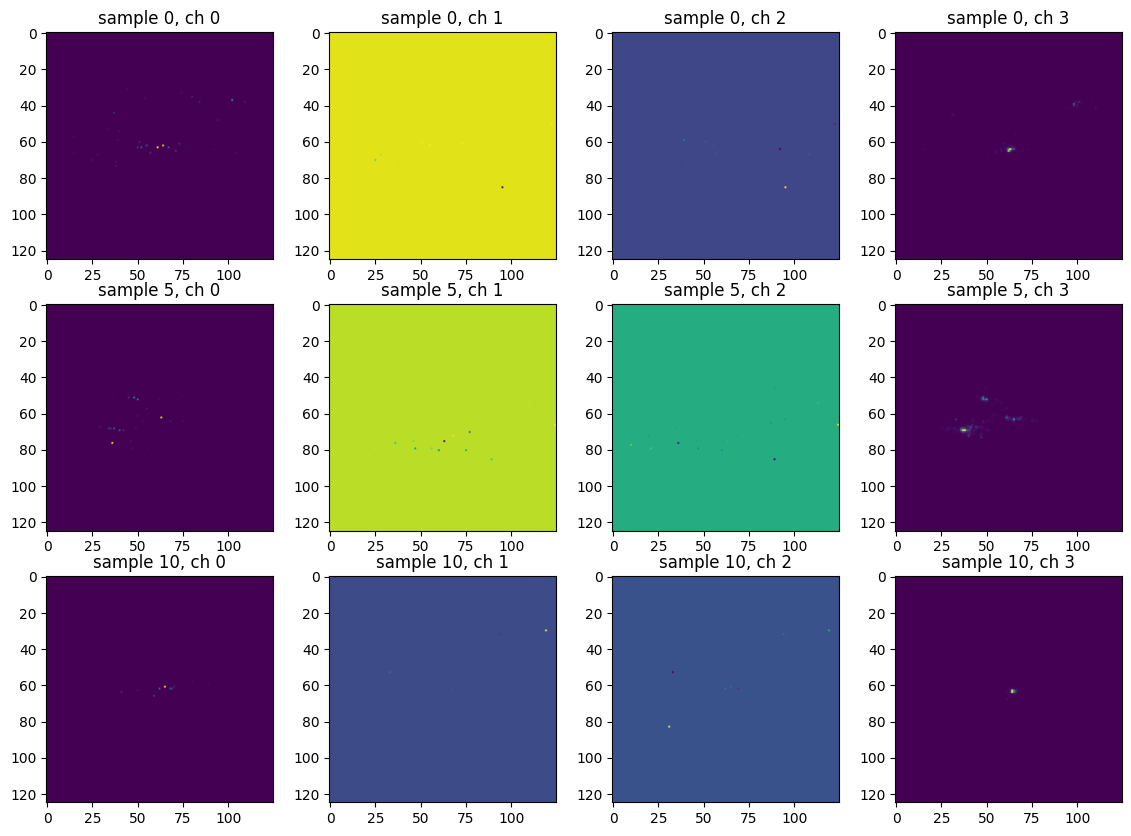

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for r, s in enumerate([0, 5, 10]):
    for c in range(4):
        ax[r, c].imshow(xs[s, c]); ax[r, c].set_title(f'sample {s}, ch {c}')
plt.savefig(f'{BASE}/channels.png', dpi=120); plt.show()

The converter and its check

In [20]:
import numpy as np, pyarrow.parquet as pq, time

PATH = '/content/top_gun_opendata_0.parquet'
pf = pq.ParquetFile(PATH)

def batch_to_arrays(batch):
    n = batch.num_rows
    flat = batch.column('X_jet').flatten().flatten().flatten().to_numpy(zero_copy_only=False)
    X = flat.reshape(n, 8, 125, 125)[:, :4]
    y = batch.column('m').to_numpy(zero_copy_only=False).astype(np.float32)
    X = np.clip(X, -60000, 60000).astype(np.float16)
    return X, y

# sanity check against slow method on sample 0
b = next(pf.iter_batches(batch_size=4, row_groups=[0,1,2,3], columns=['X_jet','m']))
Xf, yf = batch_to_arrays(b)
slow = np.array([[list(r) for r in ch] for ch in pf.read_row_group(0).to_pandas()['X_jet'].values[0]], dtype=np.float32)[:4]
print(Xf.shape, np.abs(Xf[0].astype(np.float32) - slow).max())

(4, 4, 125, 125) 0.0552063


Raw data contains rare extreme pixel values: 2 pixels in channel 0 overflowed float16 across 20,000 samples. They are clipped before the cast. The final preprocessing clips each channel again, and CMSSW inference will need to apply the same clipping.

Building the subset

In [24]:
N_BLOCKS, BLOCK = 20, 1000
total = pf.metadata.num_row_groups
starts = np.linspace(0, total - BLOCK, N_BLOCKS).astype(int)
Xs, ys = [], []
t0 = time.time()
for s in starts:
    for batch in pf.iter_batches(batch_size=500, row_groups=list(range(s, s + BLOCK)), columns=['X_jet','m']):
        X, y = batch_to_arrays(batch); Xs.append(X); ys.append(y)
    print(s, f'{time.time()-t0:.0f}s')
X = np.concatenate(Xs); y = np.concatenate(ys)
print(X.shape, y.shape, y.min(), y.max())
np.savez(f'{BASE}/subset_20k.npz', X=X, y=y)

0 4s
7859 7s
15718 12s
23577 17s
31437 21s
39296 25s
47155 30s
55015 34s
62874 37s
70733 42s
78593 46s
86452 50s
94311 54s
102171 59s
110030 63s
117889 66s
125749 71s
133608 75s
141467 79s
149327 82s
(20000, 4, 125, 125) (20000,) 85.38415 499.97604


Histogram of target for the subset

(20000, 4, 125, 125) float16 (20000,) 85.38415 499.97604 0


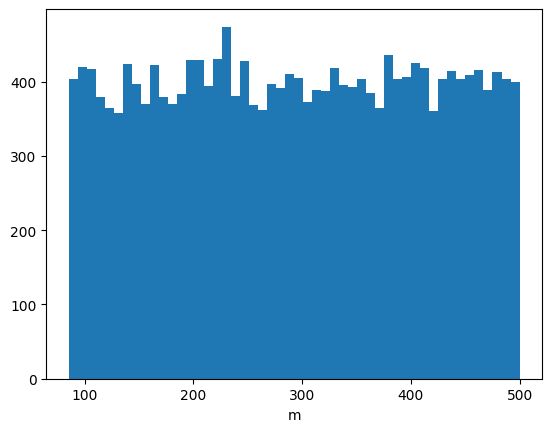

In [25]:

print(X.shape, X.dtype, y.shape, y.min(), y.max(), np.isnan(y).sum())
plt.hist(y, bins=50); plt.xlabel('m'); plt.savefig(f'{BASE}/subset_mass_hist.png', dpi=150); plt.show()

In [26]:
for c in range(4):
    print(c, 'inf:', int(np.isinf(X[:, c]).sum()), 'nan:', int(np.isnan(X[:, c]).sum()))

0 inf: 0 nan: 0
1 inf: 0 nan: 0
2 inf: 0 nan: 0
3 inf: 0 nan: 0


SPLIT

In [16]:
N = len(y)
rng = np.random.default_rng(42)
idx = rng.permutation(N)
n_test = int(0.2 * N)                # 4000
n_val  = int(0.1 * N)                # 2000
test_idx  = idx[:n_test]
val_idx   = idx[n_test:n_test + n_val]
train_idx = idx[n_test + n_val:]     # 14000
np.savez(f'{BASE}/split_20k.npz', train=train_idx, val=val_idx, test=test_idx)
print(len(train_idx), len(val_idx), len(test_idx))

14000 2000 4000


BASELINE - VAL ONLY

In [17]:
ytr, yv = y[train_idx], y[val_idx]
for name, p in [('mean', ytr.mean()), ('median', np.median(ytr))]:
    mae  = np.abs(yv - p).mean()
    rmse = np.sqrt(((yv - p) ** 2).mean())
    r2   = 1 - ((yv - p) ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
    print(name, f'MAE {mae:.2f}  RMSE {rmse:.2f}  R2 {r2:.4f}')

mean MAE 103.71  RMSE 119.74  R2 -0.0001
median MAE 103.71  RMSE 119.74  R2 -0.0001


In [27]:
d = np.load(f'{BASE}/subset_20k.npz'); s = np.load(f'{BASE}/split_20k.npz')
X, y = d['X'], d['y']
print(X.shape, X.dtype, y.shape)
print('inf:', [int(np.isinf(X[:, c]).sum()) for c in range(4)], 'nan:', int(np.isnan(X).sum()))
print(len(s['train']), len(s['val']), len(s['test']), s['train'].max())

(20000, 4, 125, 125) float16 (20000,)
inf: [0, 0, 0, 0] nan: 0
14000 2000 4000 19998
